# Stroke — Paper replication

This notebook replicates the analysis described by Wu et al., *A Machine Learning-Based Model for Stroke Prediction*, DOI: [10.54254/2755-2721/78/20240645](https://doi.org/10.54254/2755-2721/78/20240645).

It compares logistic regression, Decision Tree, Random Forest, SVM, KNN, XGBoost and a deep neural network before and after feature selection, with performance tables and paper-style figures.

The implementation uses a stratified 80/20 split. BMI imputation, correlation-based feature selection and scaling are learned from the training data only. Full-dataset correlation figures are descriptive and do not determine the predictive feature set.

Test-performance rankings are descriptive. Class-balanced logistic regression is pre-specified separately for the XAI extension.

In [ ]:
import os

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    f1_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from xgboost import XGBClassifier

In [ ]:
file_path = "../../data\\stroke\\healthcare-dataset-stroke-data.csv"

df_corr = pd.read_csv(file_path)

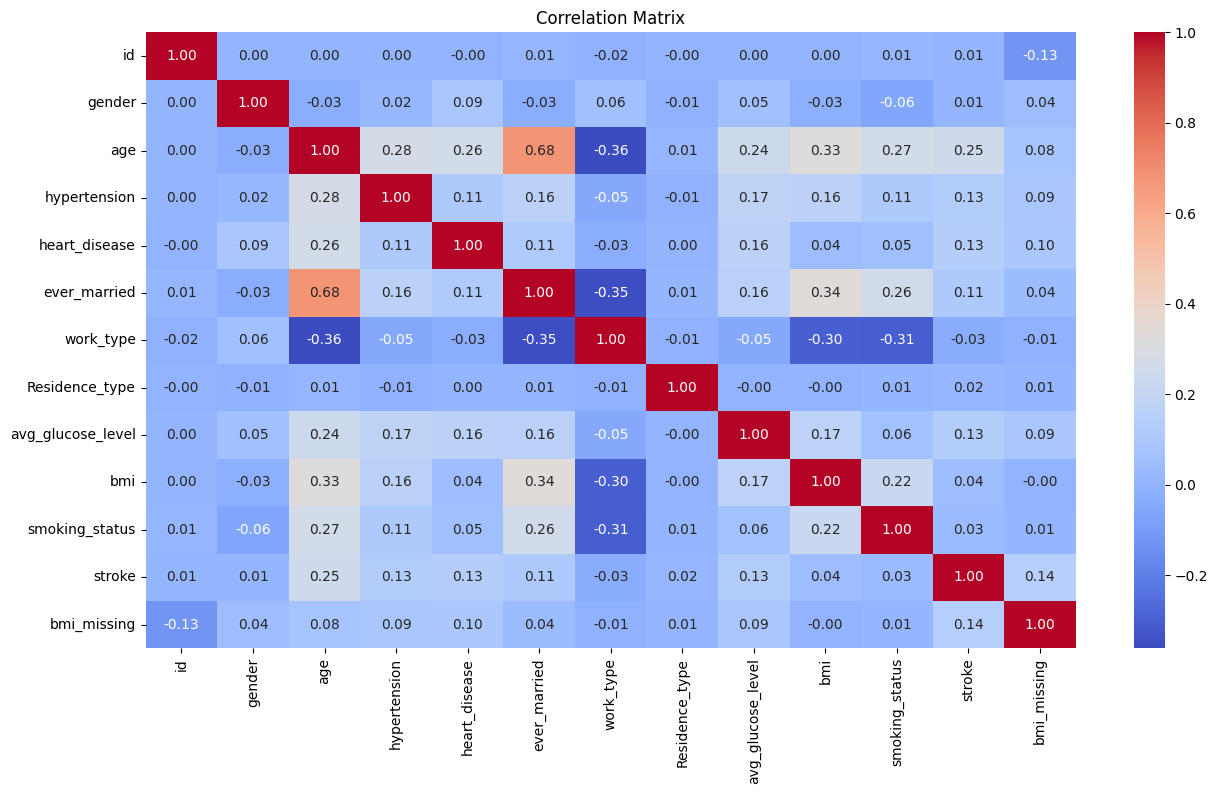

In [ ]:
df_corr = df_corr[df_corr['gender'] != 'Other']

# Record missing BMI before imputation.
df_corr['bmi_missing'] = df_corr['bmi'].isna().astype(int)

# Impute BMI after constructing the missingness indicator.
df_corr['bmi'] = df_corr['bmi'].fillna(df_corr['bmi'].mean())

# Encode categorical predictors.
df_corr['gender'] = df_corr['gender'].map({'Male': 1, 'Female': 0})
df_corr['ever_married'] = df_corr['ever_married'].map({'Yes': 1, 'No': 0})
df_corr['Residence_type'] = df_corr['Residence_type'].map({'Urban': 1, 'Rural': 0})

df_corr['work_type'] = df_corr['work_type'].astype('category').cat.codes
df_corr['smoking_status'] = df_corr['smoking_status'].astype('category').cat.codes

# Calculate the exploratory correlation matrix.
corr_matrix = df_corr.corr()

plt.figure(figsize=(15,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')

plt.title("Correlation Matrix")
plt.show()

In [ ]:
df = pd.read_csv(file_path)
df = df[df['gender'] != 'Other'].copy()
df['age'] = df['age'].astype(int)

y = df['stroke'].copy()
X_raw = df.drop(columns=['stroke', 'id']).copy()

# Split before imputation, encoding, feature selection, and scaling.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

for part in (X_train_raw, X_test_raw):
    part['bmi_missing'] = part['bmi'].isna().astype(int)

train_bmi_mean = X_train_raw['bmi'].mean()
X_train_raw['bmi'] = X_train_raw['bmi'].fillna(train_bmi_mean)
X_test_raw['bmi'] = X_test_raw['bmi'].fillna(train_bmi_mean)

categorical_cols = [
    'gender', 'smoking_status', 'Residence_type',
    'work_type', 'ever_married'
]
X_train_encoded = pd.get_dummies(
    X_train_raw, columns=categorical_cols, drop_first=False
)
X_test_encoded = pd.get_dummies(
    X_test_raw, columns=categorical_cols, drop_first=False
).reindex(columns=X_train_encoded.columns, fill_value=0)

# Learn the correlation-based feature set from training data only.
training_for_selection = X_train_encoded.copy()
training_for_selection['stroke'] = y_train.to_numpy()
training_correlations = training_for_selection.corr(numeric_only=True)['stroke'].abs()
selected_features = training_correlations[
    (training_correlations > 0.1)
    & (training_correlations.index != 'stroke')
].index.tolist()

X_train_full = X_train_encoded
X_test_full = X_test_encoded
X_train_sel = X_train_encoded[selected_features]
X_test_sel = X_test_encoded[selected_features]

In [ ]:
print('Training rows:', len(X_train_full))
print('Test rows:', len(X_test_full))
print('Full features:', X_train_full.shape[1])
print('Training-selected features:', selected_features)

Training rows: 4087
Test rows: 1022
Full features: 21
Training-selected features: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi_missing', 'ever_married_No', 'ever_married_Yes']


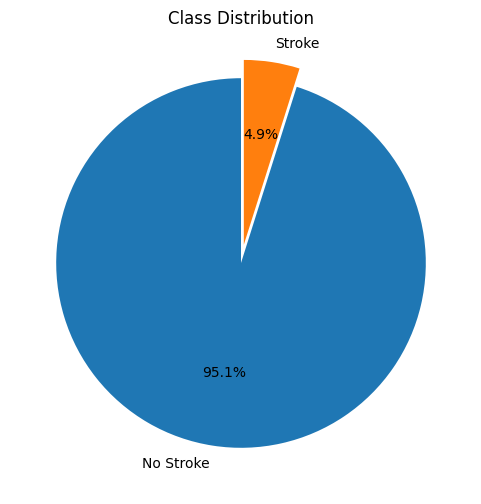

In [ ]:
counts = y.value_counts()

labels = ['No Stroke', 'Stroke']
sizes = counts.values

plt.figure(figsize=(6,6))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0, 0.1]
)

plt.title("Class Distribution")
plt.show()

In [ ]:
scaler_full = StandardScaler()
X_train_full = pd.DataFrame(
    scaler_full.fit_transform(X_train_full),
    columns=X_train_encoded.columns, index=X_train_encoded.index
)
X_test_full = pd.DataFrame(
    scaler_full.transform(X_test_full),
    columns=X_train_encoded.columns, index=X_test_encoded.index
)

scaler_sel = StandardScaler()
X_train_sel = pd.DataFrame(
    scaler_sel.fit_transform(X_train_sel),
    columns=selected_features, index=X_train_encoded.index
)
X_test_sel = pd.DataFrame(
    scaler_sel.transform(X_test_sel),
    columns=selected_features, index=X_test_encoded.index
)

In [ ]:

def evaluate(y_true, y_pred, y_scores):
    """Calculate thresholded and ranking metrics on held-out predictions.

    Args:
        y_true: Observed binary outcome labels.
        y_pred: Predicted binary class labels.
        y_scores: Continuous positive-class scores used to construct the ROC curve.

    Returns:
        Accuracy, F1 score, recall, false-positive rates, true-positive rates,
        and ROC AUC, in that order.
    """
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    return acc, f1, recall, fpr, tpr, roc_auc

In [ ]:
def run_models(X_train, X_test, y_train, y_test):
    """Fit the classical candidate models and evaluate held-out predictions.

    Args:
        X_train: Training feature matrix.
        X_test: Held-out feature matrix.
        y_train: Training outcome labels.
        y_test: Held-out outcome labels.

    Returns:
        A mapping from model names to metric tuples returned by ``evaluate``.
    """

    # Any resampling is restricted to the training partition.

    results = {}

    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    y_scores = lr.predict_proba(X_test)[:,1]
    results["Logistic Regression"] = evaluate(y_test, y_pred, y_scores)

    dt = DecisionTreeClassifier()
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_test)
    y_scores = dt.predict_proba(X_test)[:,1]
    results["Decision Tree"] = evaluate(y_test, y_pred, y_scores)

    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    y_scores = rf.predict_proba(X_test)[:,1]
    results["Random Forest"] = evaluate(y_test, y_pred, y_scores)

    svm = SVC(probability=True)
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)
    y_scores = svm.predict_proba(X_test)[:,1]
    results["SVM"] = evaluate(y_test, y_pred, y_scores)

    knn = KNeighborsClassifier()
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    y_scores = knn.predict_proba(X_test)[:,1]
    results["KNN"] = evaluate(y_test, y_pred, y_scores)

    try:
        xgb = XGBClassifier(eval_metric='logloss')
        xgb.fit(X_train, y_train)
        y_pred = xgb.predict(X_test)
        y_scores = xgb.predict_proba(X_test)[:,1]
        results["XGBoost"] = evaluate(y_test, y_pred, y_scores)
    except:
        print("XGBoost not installed")

    return results

In [ ]:
results_before = run_models(X_train_full, X_test_full, y_train, y_test)
results_after = run_models(X_train_sel, X_test_sel, y_train, y_test)

In [ ]:
def run_dnn(X_train, X_test, y_train, y_test):
    """Fit the neural-network candidate and evaluate held-out predictions.

    Args:
        X_train: Training feature matrix.
        X_test: Held-out feature matrix.
        y_train: Training outcome labels.
        y_test: Held-out outcome labels.

    Returns:
        The metric tuple returned by ``evaluate`` for the fitted network.
    """
    # Any resampling is restricted to the training partition.

    model = Sequential()
    model.add(Input(shape=(X_train.shape[1],)))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=20, batch_size=50, verbose=0)

    y_scores = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_scores > 0.5).astype(int)

    return evaluate(y_test, y_pred, y_scores)

In [ ]:
results_before["DNN"] = run_dnn(X_train_full, X_test_full, y_train, y_test)
results_after["DNN"] = run_dnn(X_train_sel, X_test_sel, y_train, y_test)


 1/32 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step



 1/32 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [ ]:
def plot_results(results, title):
    """Plot four evaluation metrics for the fitted model candidates.

    Args:
        results: Mapping from model names to metric tuples returned by ``evaluate``.
        title: Overall title displayed above the four-panel figure.

    Returns:
        None. The comparison figure is displayed as a notebook output.
    """
    plot_models = [
        "Logistic Regression",
        "SVM",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ]

    model_colors = {
        "Logistic Regression": "#4c4a86",
        "SVM": "#6783c1",
        "KNN": "#dbe4f0",
        "Decision Tree": "#e5a39b",
        "Random Forest": "#514c88",
        "XGBoost": "#6e89c9"
    }

    colors = [model_colors[m] for m in plot_models]

    acc = [results[m][0] for m in plot_models]
    f1 = [results[m][1] for m in plot_models]
    recall = [results[m][2] for m in plot_models]
    aucs = [results[m][5] for m in plot_models]

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    axs[0, 0].bar(plot_models, aucs, color=colors)
    axs[0, 0].set_title("AUC Comparison")
    axs[0, 0].set_ylabel("AUC")

    axs[0, 1].bar(plot_models, acc, color=colors)
    axs[0, 1].set_title("Accuracy Comparison")
    axs[0, 1].set_ylabel("Accuracy")

    axs[1, 0].bar(plot_models, f1, color=colors)
    axs[1, 0].set_title("F1 Comparison")
    axs[1, 0].set_ylabel("F1")

    axs[1, 1].bar(plot_models, recall, color=colors)
    axs[1, 1].set_title("Recall Comparison")
    axs[1, 1].set_ylabel("Recall")

    for ax in axs.flat:
        ax.tick_params(axis='x', rotation=45)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

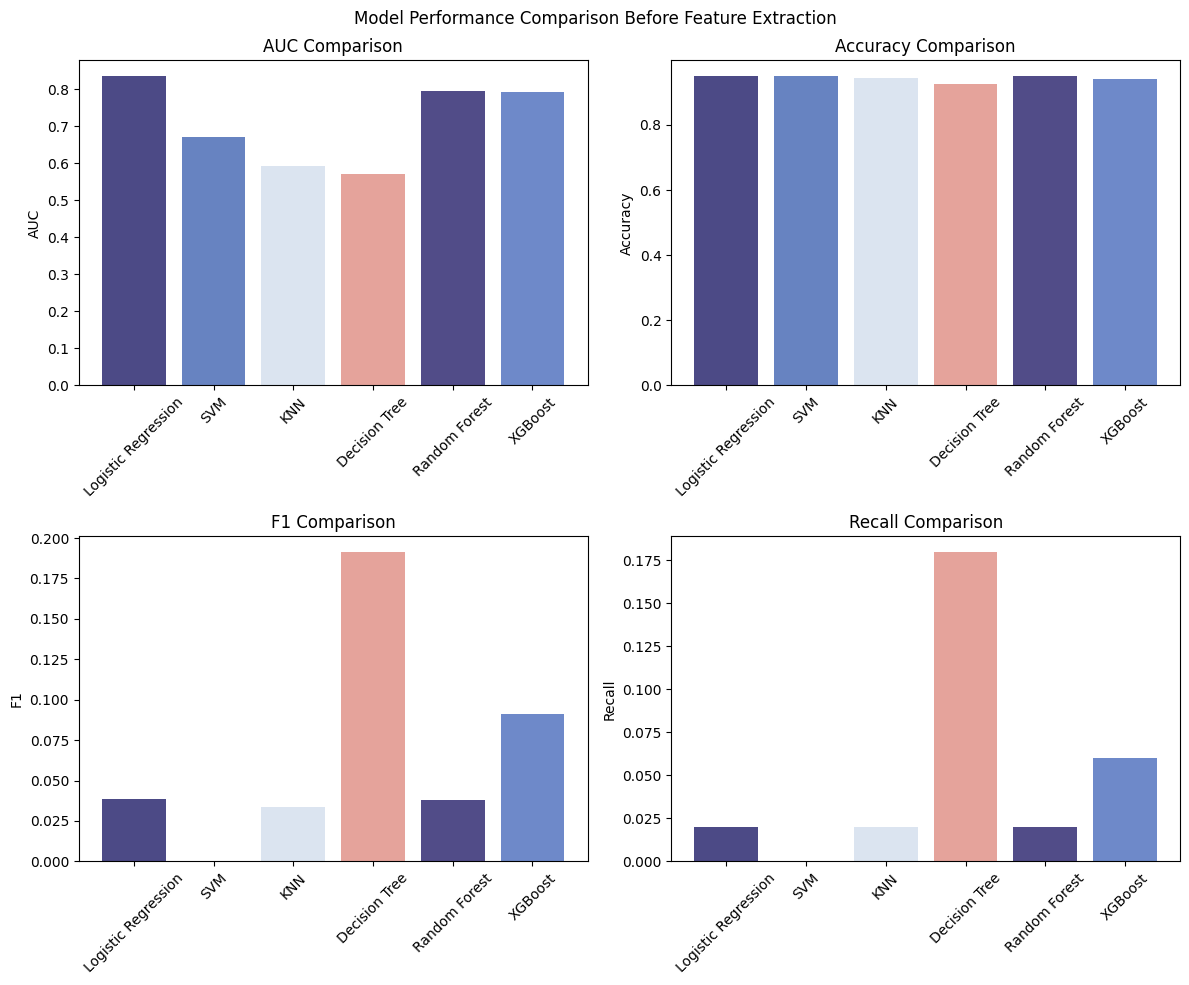

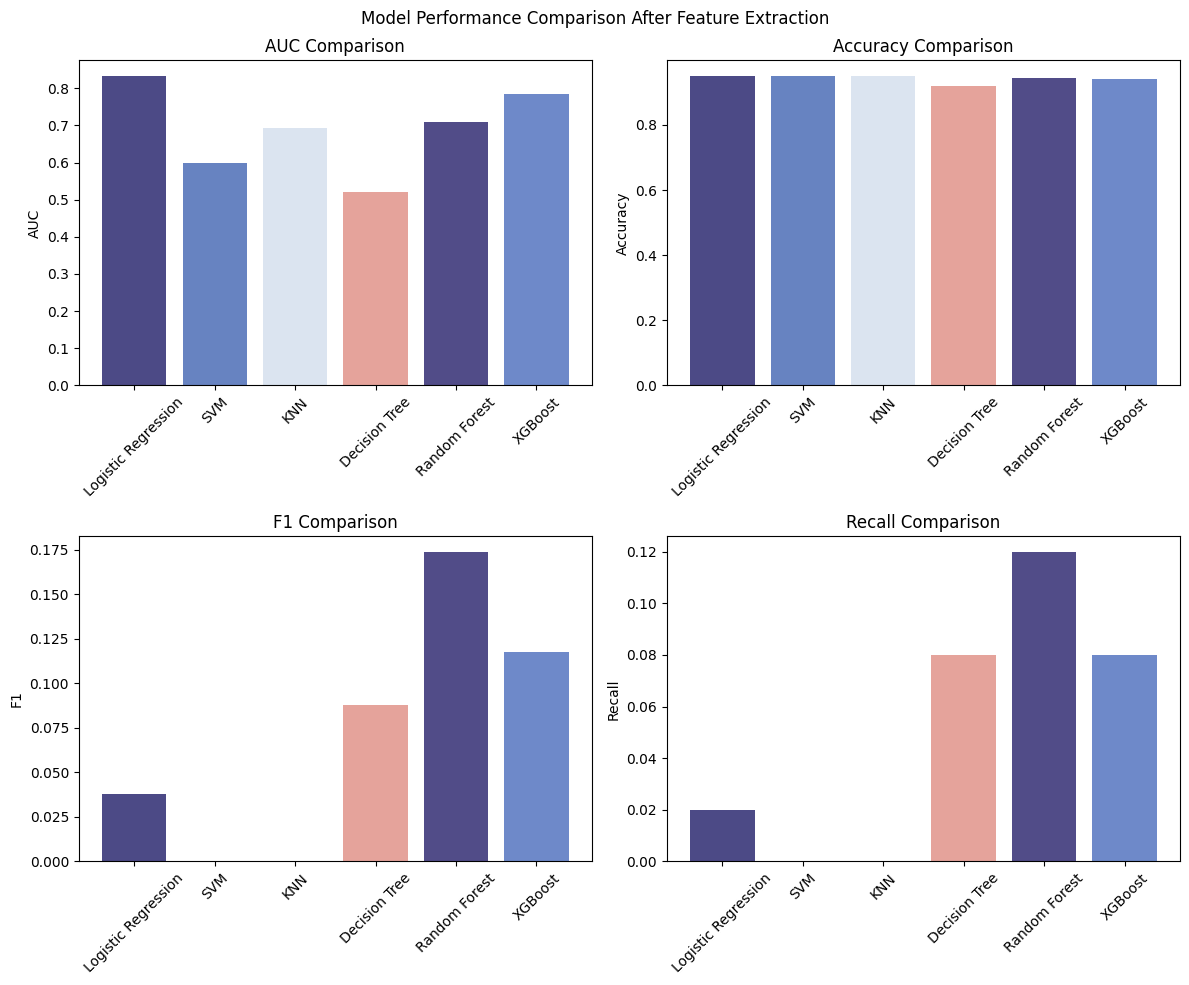

In [ ]:
plot_results(results_before, "Model Performance Comparison Before Feature Extraction")
plot_results(results_after, "Model Performance Comparison After Feature Extraction")

In [ ]:

dnn_before = results_before["DNN"]
dnn_after = results_after["DNN"]

dnn_table = pd.DataFrame({
    "Metric": ["Accuracy", "AUC"],
    "Before Feature Extraction": [round(dnn_before[0], 4), round(dnn_before[5], 4)],
    "After Feature Extraction": [round(dnn_after[0], 4), round(dnn_after[5], 4)]
})

print(dnn_table)

     Metric  Before Feature Extraction  After Feature Extraction
0  Accuracy                     0.9501                    0.9481
1       AUC                     0.8039                    0.8315


## Repeated paper-style comparison (existing seeded run)

In [ ]:
# Set deterministic seeds for the repeated comparison.
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# The leakage-controlled train/test matrices created above are reused.
# Reproducibility seeds apply to the repeated model comparison below.

In [ ]:
# Split, training-only imputation, training-only feature selection, and
# training-only scaling were completed once above.

In [ ]:
# Define the evaluation functions.
def evaluate(y_true, y_pred, y_scores):
    """Calculate thresholded and ranking metrics on held-out predictions.

    Args:
        y_true: Observed binary outcome labels.
        y_pred: Predicted binary class labels.
        y_scores: Continuous positive-class scores used to construct the ROC curve.

    Returns:
        Accuracy, F1 score, recall, false-positive rates, true-positive rates,
        and ROC AUC, in that order.
    """
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    return acc, f1, recall, fpr, tpr, roc_auc

In [ ]:
def run_models(X_train, X_test, y_train, y_test):
    """Fit the classical candidates and retain both metrics and estimators.

    Args:
        X_train: Training feature matrix.
        X_test: Held-out feature matrix.
        y_train: Training outcome labels.
        y_test: Held-out outcome labels.

    Returns:
        A pair containing the model-to-metrics mapping and the corresponding
        mapping of model names to fitted estimators.
    """
    results = {}
    trained_models = {}

    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train, y_train)
    trained_models["Logistic Regression"] = lr
    y_pred = lr.predict(X_test)
    y_scores = lr.predict_proba(X_test)[:, 1]
    results["Logistic Regression"] = evaluate(y_test, y_pred, y_scores)

    dt = DecisionTreeClassifier()
    dt.fit(X_train, y_train)
    trained_models["Decision Tree"] = dt
    y_pred = dt.predict(X_test)
    y_scores = dt.predict_proba(X_test)[:, 1]
    results["Decision Tree"] = evaluate(y_test, y_pred, y_scores)

    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)
    trained_models["Random Forest"] = rf
    y_pred = rf.predict(X_test)
    y_scores = rf.predict_proba(X_test)[:, 1]
    results["Random Forest"] = evaluate(y_test, y_pred, y_scores)

    svm = SVC(probability=True)
    svm.fit(X_train, y_train)
    trained_models["SVM"] = svm
    y_pred = svm.predict(X_test)
    y_scores = svm.predict_proba(X_test)[:, 1]
    results["SVM"] = evaluate(y_test, y_pred, y_scores)

    knn = KNeighborsClassifier()
    knn.fit(X_train, y_train)
    trained_models["KNN"] = knn
    y_pred = knn.predict(X_test)
    y_scores = knn.predict_proba(X_test)[:, 1]
    results["KNN"] = evaluate(y_test, y_pred, y_scores)

    xgb = XGBClassifier(eval_metric='logloss')
    xgb.fit(X_train, y_train)
    trained_models["XGBoost"] = xgb
    y_pred = xgb.predict(X_test)
    y_scores = xgb.predict_proba(X_test)[:, 1]
    results["XGBoost"] = evaluate(y_test, y_pred, y_scores)

    return results, trained_models

results_before, models_before = run_models(X_train_full, X_test_full, y_train, y_test)
results_after, models_after = run_models(X_train_sel, X_test_sel, y_train, y_test)

In [ ]:
performance = pd.DataFrame({
    "Model": results_after.keys(),
    "AUC": [v[5] for v in results_after.values()]
})

performance = performance.sort_values(
    "AUC",
    ascending=False
)

print(performance)

                 Model       AUC
0  Logistic Regression  0.833807
5              XGBoost  0.785792
2        Random Forest  0.719619
4                  KNN  0.693354
3                  SVM  0.598807
1        Decision Tree  0.519938


In [ ]:
test_auc_leader = performance.iloc[0]["Model"]
print(f"Highest observed test AUC (descriptive only): {test_auc_leader}")

Highest observed test AUC (descriptive only): Logistic Regression


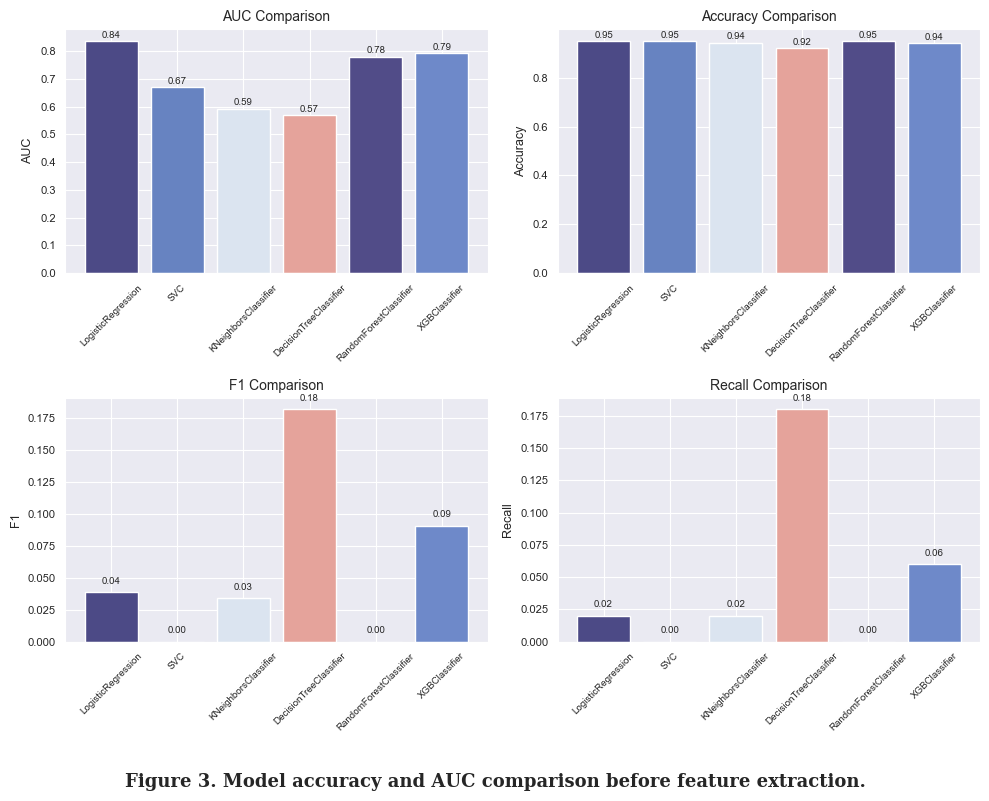

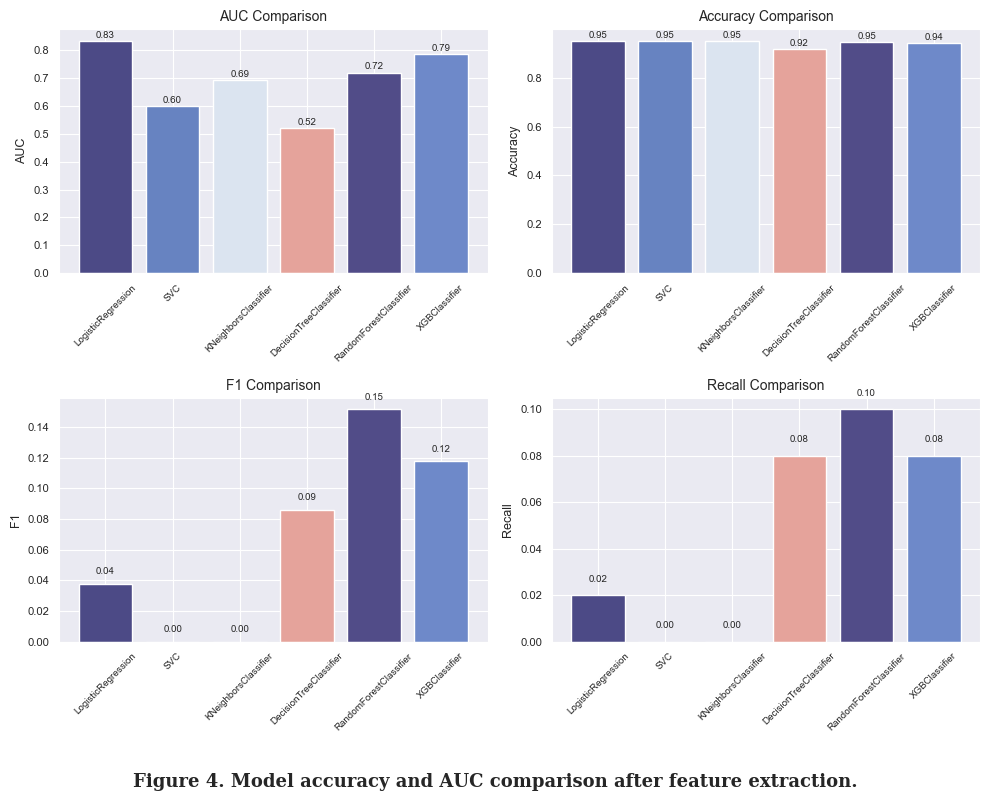

In [ ]:
# Reproduce the paper-style comparison plot.
def plot_results_paper_style(results, caption_text):
    """Plot model metrics using the layout adopted for the replication.

    Args:
        results: Mapping from model names to metric tuples returned by ``evaluate``.
        caption_text: Caption-like text displayed beneath the four panels.

    Returns:
        None. The formatted comparison figure is displayed as notebook output.
    """
    sns.set_style("darkgrid")

    plot_models = [
        "Logistic Regression",
        "SVM",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ]

    label_map = {
        "Logistic Regression": "LogisticRegression",
        "SVM": "SVC",
        "KNN": "KNeighborsClassifier",
        "Decision Tree": "DecisionTreeClassifier",
        "Random Forest": "RandomForestClassifier",
        "XGBoost": "XGBClassifier"
    }

    display_labels = [label_map[m] for m in plot_models]

    model_colors = [
        "#4c4a86",
        "#6783c1",
        "#dbe4f0",
        "#e5a39b",
        "#514c88",
        "#6e89c9"
    ]

    acc = [results[m][0] for m in plot_models]
    f1 = [results[m][1] for m in plot_models]
    recall = [results[m][2] for m in plot_models]
    aucs = [results[m][5] for m in plot_models]

    fig, axs = plt.subplots(2, 2, figsize=(10, 8))

    metric_info = [
        ("AUC Comparison", aucs, "AUC"),
        ("Accuracy Comparison", acc, "Accuracy"),
        ("F1 Comparison", f1, "F1"),
        ("Recall Comparison", recall, "Recall")
    ]

    for ax, (title, values, ylabel) in zip(axs.flat, metric_info):
        bars = ax.bar(display_labels, values, color=model_colors)
        ax.set_title(title, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.tick_params(axis='x', rotation=45, labelsize=7)
        ax.tick_params(axis='y', labelsize=8)

        for bar, val in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f"{val:.2f}",
                ha='center',
                va='bottom',
                fontsize=7
            )

    plt.figtext(
        0.5, 0.01,
        caption_text,
        ha='center',
        fontsize=13,
        fontweight='bold',
        family='serif'
    )

    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

plot_results_paper_style(
    results_before,
    "Figure 3. Model accuracy and AUC comparison before feature extraction."
)

plot_results_paper_style(
    results_after,
    "Figure 4. Model accuracy and AUC comparison after feature extraction."
)

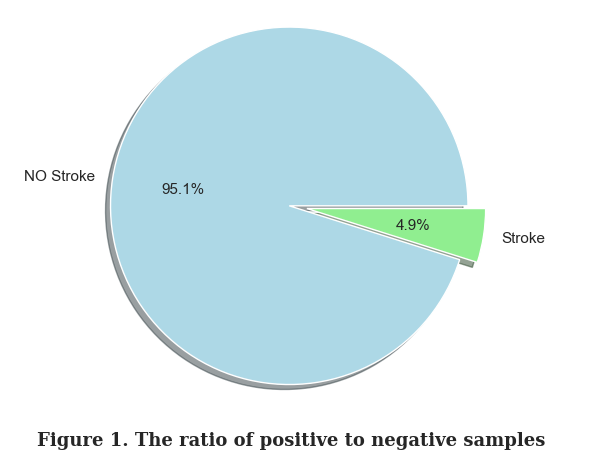

In [ ]:
counts = y.value_counts().sort_index()
# Class 0 denotes no stroke and class 1 denotes stroke.
sizes = [counts[0], counts[1]]
labels = ['NO Stroke', 'Stroke']
colors = ['#add8e6', '#90ee90']

fig, ax = plt.subplots(figsize=(6.2, 4.6))

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=0,
    explode=(0, 0.1),
    shadow=True,
    textprops={'fontsize': 11}
)

ax.axis('equal')

plt.figtext(
    0.5, 0.02,
    'Figure 1. The ratio of positive to negative samples',
    ha='center',
    fontsize=13,
    fontweight='bold',
    family='serif'
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

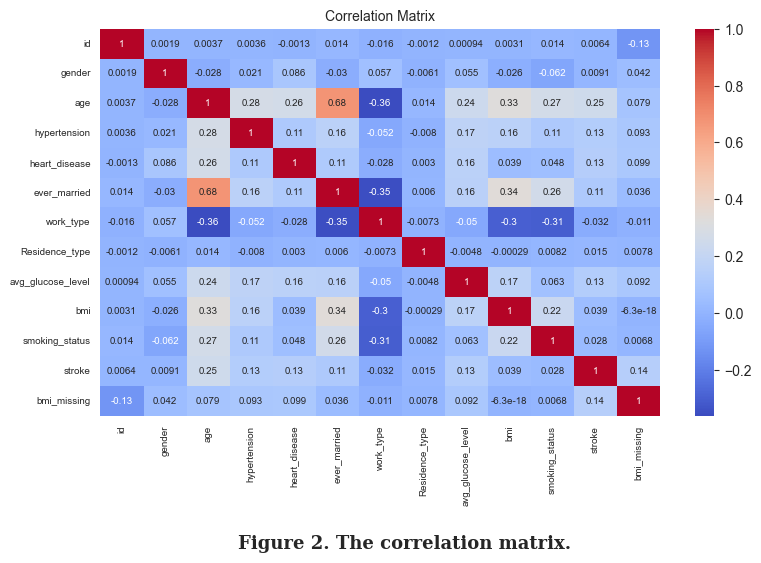

In [ ]:

file_path = "../../data/stroke/healthcare-dataset-stroke-data.csv"
df_corr = pd.read_csv(file_path)

df_corr = df_corr[df_corr['gender'] != 'Other'].copy()

df_corr['bmi_missing'] = df_corr['bmi'].isna().astype(int)

df_corr['bmi'] = df_corr['bmi'].fillna(df_corr['bmi'].mean())

df_corr['gender'] = df_corr['gender'].map({'Male': 1, 'Female': 0})
df_corr['ever_married'] = df_corr['ever_married'].map({'Yes': 1, 'No': 0})
df_corr['Residence_type'] = df_corr['Residence_type'].map({'Urban': 1, 'Rural': 0})
df_corr['work_type'] = df_corr['work_type'].astype('category').cat.codes
df_corr['smoking_status'] = df_corr['smoking_status'].astype('category').cat.codes

corr_matrix = df_corr.corr()

fig, ax = plt.subplots(figsize=(8.2, 5.6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2g",
    cmap="coolwarm",
    cbar=True,
    annot_kws={"size": 7},
    ax=ax
)

ax.set_title("Correlation Matrix", fontsize=10)
ax.tick_params(axis='x', labelrotation=90, labelsize=7)
ax.tick_params(axis='y', labelsize=7)

plt.figtext(
    0.5, 0.01,
    'Figure 2. The correlation matrix.',
    ha='center',
    fontsize=13,
    fontweight='bold',
    family='serif'
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

In [ ]:

def run_dnn(X_train, X_test, y_train, y_test):
    """Fit the neural-network candidate and return headline test metrics.

    Args:
        X_train: Training feature matrix.
        X_test: Held-out feature matrix.
        y_train: Training outcome labels.
        y_test: Held-out outcome labels.

    Returns:
        A pair containing held-out accuracy and ROC AUC.
    """
    model = Sequential()
    model.add(Input(shape=(X_train.shape[1],)))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=20, batch_size=50, verbose=0)

    y_scores = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_scores > 0.5).astype(int)

    acc = accuracy_score(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_scores)
    roc_auc = auc(fpr, tpr)

    return acc, roc_auc

# Evaluate the neural-network configurations.
dnn_before_acc, dnn_before_auc = run_dnn(X_train_full, X_test_full, y_train, y_test)
dnn_after_acc, dnn_after_auc = run_dnn(X_train_sel, X_test_sel, y_train, y_test)

dnn_table = pd.DataFrame({
    "Metric": ["Accuracy", "AUC"],
    "Before Feature Extraction": [round(dnn_before_acc, 4), round(dnn_before_auc, 4)],
    "After Feature Extraction": [round(dnn_after_acc, 4), round(dnn_after_auc, 4)]
})

print(dnn_table)


 1/32 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step



 1/32 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step


27/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


     Metric  Before Feature Extraction  After Feature Extraction
0  Accuracy                     0.9511                    0.9481
1       AUC                     0.8080                    0.8323

## Interpretation

The strong class imbalance makes accuracy an incomplete description of model behaviour. Logistic regression produced the highest held-out ROC-AUC among the evaluated classical models after training-only feature selection. The corrected branch fits imputation, encoding, feature selection, and scaling using the training partition only. The retained `bmi_missing` indicator is an audit finding about the data-recording process and should not be interpreted as a biological effect of missingness.
